In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from initial_state import ValidationSpec
from controllers.sindy_mpc import SINDyMPCController
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics

# Reuse the same validation spec generated by 05a so results are
# directly comparable with the SINDy-LQR stress test.
VAL_SPEC         = ROOT / "artifacts/validation/sindy_lqr_val_spec.npz"
LQR_METRICS      = ROOT / "artifacts/validation/sindy_lqr_stress_metrics.npz"
MPC_ARTIFACT     = ROOT / "artifacts/controllers/sindy_mpc.pkl"
MPC_ROLLOUTS     = ROOT / "artifacts/validation/sindy_mpc_stress_rollouts.npz"
MPC_METRICS      = ROOT / "artifacts/validation/sindy_mpc_stress_metrics.npz"

T_END       = 20.0
DT          = 0.02
FORCE_LIMIT = 5.0

## 1. Load Validation Spec

Reuses the 100-case spec from `05a_sindy_lqr_stress_test.ipynb` (seed=42, same initial
conditions) so SINDy-MPC and SINDy-LQR are evaluated on identical starting states.

In [2]:
if not VAL_SPEC.exists():
    raise FileNotFoundError(
        f"{VAL_SPEC} not found.\n"
        "Run notebooks/05a_sindy_lqr_stress_test.ipynb first."
    )
spec = ValidationSpec.load(VAL_SPEC)
feas = spec.feasible
print(f"Loaded spec: {spec.n_feasible}/{spec.n} feasible cases  (seed={spec.seed})")
print(f"  force range: [{spec.forces[feas].min():.2f}, {spec.forces[feas].max():.2f}] N")
print(f"  angle range: [{spec.angles_deg[feas].min():.1f}, {spec.angles_deg[feas].max():.1f}] deg")

Loaded spec: 100/100 feasible cases  (seed=42)
  force range: [0.53, 4.89] N
  angle range: [6.8, 89.4] deg


## 2. Load SINDy-MPC Controller

In [3]:
if not MPC_ARTIFACT.exists():
    raise FileNotFoundError(
        f"{MPC_ARTIFACT} not found.\n"
        "Run notebooks/07_sindy_mpc.ipynb first."
    )
controller = SINDyMPCController.load(MPC_ARTIFACT)
print(f"Loaded SINDy-MPC controller  "
      f"(horizon={controller.metadata.get('horizon')}  "
      f"force_limit={controller.force_limit} N)")
print("Equations:")
for eq in controller.metadata["model"]["equations"]:
    print(" ", eq)

Loaded SINDy-MPC controller  (horizon=20  force_limit=5.0 N)
Equations:
  x_next = 1*x + 0.01003*x_dot
  x_dot_next = 0.9999*x_dot + 0.007078*u + -0.02327*sin(theta)
  theta_next = 1*theta + 0.01002*theta_dot
  theta_dot_next = 0.9998*theta_dot + 0.2135*sin(theta) + 0.01827*u*cos(theta)


## 3. Run 100 Rollouts

In [4]:
n_steps = int(round(T_END / DT)) + 1

if MPC_ROLLOUTS.exists():
    _d = np.load(MPC_ROLLOUTS)
    states_arr = _d["states"]
    inputs_arr = _d["inputs"]
    t_arr      = _d["t"]
    rollout_ok = _d["success"].astype(bool)
    print(f"Loaded rollouts from {MPC_ROLLOUTS}")
else:
    states_arr = np.full((spec.n, 4, n_steps), np.nan)
    inputs_arr = np.full((spec.n, n_steps), np.nan)
    t_arr      = None
    rollout_ok = np.zeros(spec.n, dtype=bool)

    for i in range(spec.n):
        if not spec.feasible[i]:
            continue
        result = rollout_controller(
            controller, spec.initial_states[i],
            t_end=T_END, dt=DT, force_limit=FORCE_LIMIT,
        )
        if t_arr is None:
            t_arr = result.t
        states_arr[i] = result.y
        inputs_arr[i] = result.u
        rollout_ok[i] = result.success
        if (i + 1) % 10 == 0:
            print(f"  {i + 1}/{spec.n} complete")

    if t_arr is None:
        t_arr = np.arange(0.0, T_END + 0.5 * DT, DT)

    MPC_ROLLOUTS.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        MPC_ROLLOUTS,
        states=states_arr, inputs=inputs_arr,
        t=t_arr, success=rollout_ok,
    )
    print(f"Saved rollouts to {MPC_ROLLOUTS}")

print(f"  rollout_ok: {rollout_ok.sum()} / {spec.feasible.sum()} feasible cases")

  10/100 complete
  20/100 complete


/Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/.venv/lib/python3.12/site-packages/cvxpy/problems/problem.py:1510: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


  30/100 complete
  40/100 complete
  50/100 complete
  60/100 complete
  70/100 complete
  80/100 complete
  90/100 complete
  100/100 complete
Saved rollouts to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_mpc_stress_rollouts.npz
  rollout_ok: 100 / 100 feasible cases


## 4. Metrics Summary

In [5]:
records = []
for i in range(spec.n):
    row = {
        "case": i,
        "force_N":   float(spec.forces[i]),
        "angle_deg": float(spec.angles_deg[i]),
        "feasible":  bool(spec.feasible[i]),
    }
    if spec.feasible[i] and rollout_ok[i]:
        m = rollout_metrics(t_arr, states_arr[i], inputs_arr[i])
        row.update(m)
    records.append(row)

feas_records = [r for r in records if r["feasible"] and "success" in r]
n_feas  = len(feas_records)
n_succ  = sum(1 for r in feas_records if r.get("success"))
n_nofall = sum(1 for r in feas_records if r.get("no_fall"))
costs   = [r["cost"] for r in feas_records if "cost" in r]
st      = [r["settle_and_remain_time"] for r in feas_records
           if r.get("settle_and_remain_time") is not None]

print("=" * 52)
print("SINDy-MPC Stress Test — 100 Random Initial Conditions")
print("=" * 52)
print(f"  Feasible cases:    {n_feas} / {spec.n}")
print(f"  Success rate:      {n_succ}/{n_feas}  "
      f"({100 * n_succ / max(1, n_feas):.1f}%)")
print(f"  No-fall rate:      {n_nofall}/{n_feas}  "
      f"({100 * n_nofall / max(1, n_feas):.1f}%)")
if costs:
    print(f"  Cost:             median={np.median(costs):.1f}  "
          f"mean={np.mean(costs):.1f}  max={np.max(costs):.1f}")
if st:
    print(f"  Settle time (s):  median={np.median(st):.2f}  "
          f"mean={np.mean(st):.2f}  max={np.max(st):.2f}")

SINDy-MPC Stress Test — 100 Random Initial Conditions
  Feasible cases:    100 / 100
  Success rate:      5/100  (5.0%)
  No-fall rate:      5/100  (5.0%)
  Cost:             median=354321.3  mean=333026.0  max=362309.9
  Settle time (s):  median=3.08  mean=2.98  max=3.30


## 5. LQR vs MPC Comparison

Side-by-side success rates on the same 100 initial conditions.

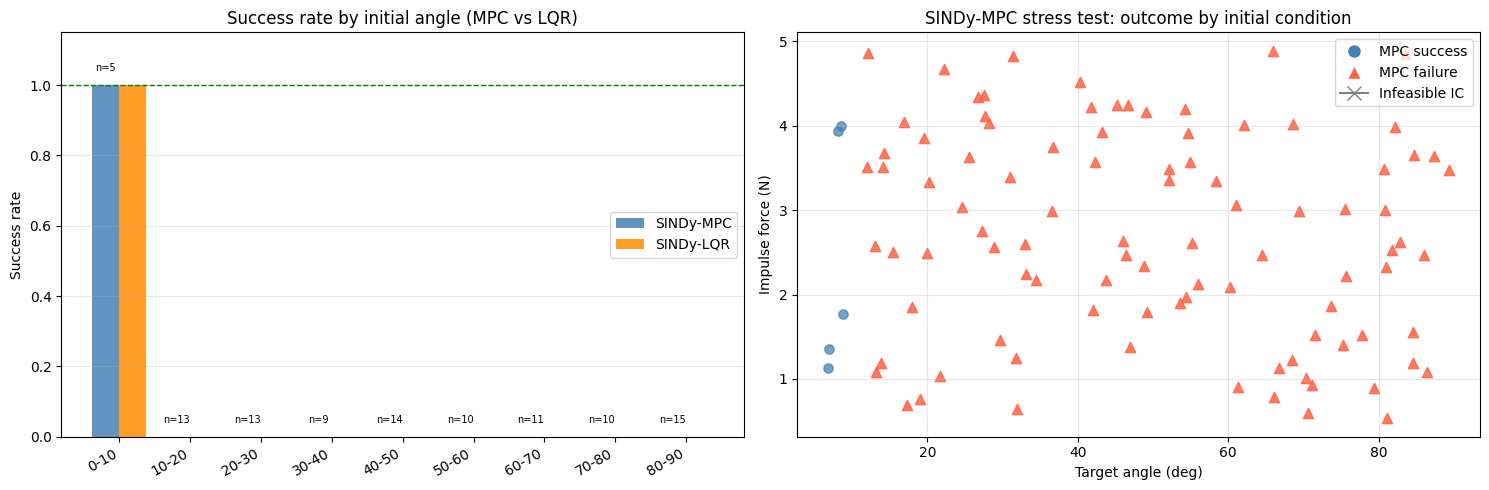

In [6]:
angle_bins  = np.arange(0, 100, 10)
force_bins  = np.arange(0.5, 5.6, 0.5)

lqr_m = np.load(LQR_METRICS) if LQR_METRICS.exists() else None


def _succ_rate(bucket_records):
    n = len(bucket_records)
    return sum(1 for r in bucket_records if r.get("success")) / n if n > 0 else np.nan


mpc_a_rates, lqr_a_rates, a_counts = [], [], []
for lo, hi in zip(angle_bins[:-1], angle_bins[1:]):
    bucket = [r for r in feas_records if lo <= r["angle_deg"] < hi]
    a_counts.append(len(bucket))
    mpc_a_rates.append(_succ_rate(bucket))
    if lqr_m is not None:
        lqr_bucket_succ = [
            float(lqr_m["success"][i])
            for i in range(spec.n)
            if spec.feasible[i]
            and lo <= float(spec.angles_deg[i]) < hi
            and np.isfinite(lqr_m["success"][i])
        ]
        lqr_a_rates.append(np.mean(lqr_bucket_succ) if lqr_bucket_succ else np.nan)
    else:
        lqr_a_rates.append(np.nan)

x_pos   = np.arange(len(angle_bins) - 1)
width   = 0.38
labels  = [f"{int(b)}-{int(b+10)}" for b in angle_bins[:-1]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Angle comparison
ax = axes[0]
bars = ax.bar(x_pos - width / 2, mpc_a_rates, width=width,
              color="steelblue", alpha=0.85, label="SINDy-MPC")
if any(not np.isnan(v) for v in lqr_a_rates):
    ax.bar(x_pos + width / 2, lqr_a_rates, width=width,
           color="darkorange", alpha=0.85, label="SINDy-LQR")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylabel("Success rate")
ax.set_title("Success rate by initial angle (MPC vs LQR)")
ax.set_ylim(0, 1.15)
ax.axhline(1.0, color="green", linestyle="--", linewidth=1)
ax.legend()
ax.grid(axis="y", alpha=0.3)
for bar, n in zip(bars, a_counts):
    if n > 0:
        ax.text(bar.get_x() + bar.get_width() / 2,
                (bar.get_height() or 0) + 0.04,
                f"n={n}", ha="center", fontsize=7)

# Scatter: MPC outcomes
ax2 = axes[1]
for r in records:
    if not r["feasible"]:
        ax2.scatter(r["angle_deg"], r["force_N"],
                    marker="x", color="gray", s=40, linewidths=1.2)
    elif r.get("success"):
        ax2.scatter(r["angle_deg"], r["force_N"],
                    marker="o", color="steelblue", s=45, alpha=0.75)
    else:
        ax2.scatter(r["angle_deg"], r["force_N"],
                    marker="^", color="tomato", s=55, alpha=0.85)
legend_els = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue",
           markersize=10, label="MPC success"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="tomato",
           markersize=10, label="MPC failure"),
    Line2D([0], [0], marker="x", color="gray", markersize=10, label="Infeasible IC"),
]
ax2.legend(handles=legend_els, loc="upper right")
ax2.set_xlabel("Target angle (deg)")
ax2.set_ylabel("Impulse force (N)")
ax2.set_title("SINDy-MPC stress test: outcome by initial condition")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## 6. Save Artifacts

In [7]:
def _to_float(v):
    if v is None:
        return np.nan
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan


metrics_to_save = {
    "force_N":            spec.forces,
    "angle_deg":          spec.angles_deg,
    "feasible":           spec.feasible.astype(float),
    "success":            np.array([float(r.get("success", np.nan))  for r in records]),
    "no_fall":            np.array([float(r.get("no_fall", np.nan))  for r in records]),
    "settle_and_remain_time": np.array(
        [_to_float(r.get("settle_and_remain_time")) for r in records]
    ),
    "cost":               np.array([_to_float(r.get("cost"))               for r in records]),
    "max_abs_theta":      np.array([_to_float(r.get("max_abs_theta"))      for r in records]),
    "control_energy":     np.array([_to_float(r.get("control_energy"))     for r in records]),
    "mean_abs_force":     np.array([_to_float(r.get("mean_abs_force"))     for r in records]),
    "settled_fraction":   np.array([_to_float(r.get("settled_fraction"))   for r in records]),
}
MPC_METRICS.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(MPC_METRICS, **metrics_to_save)
print(f"Saved metrics to {MPC_METRICS}")

Saved metrics to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_mpc_stress_metrics.npz
